# Project 11: Image Classification with CNN
Dataset: CIFAR-10 (60,000 small colour images, 10 classes)

## Imports and folders


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix

os.makedirs("images", exist_ok=True)
os.makedirs("models", exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


#### loading data

In [2]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# labels come as shape (N, 1), so flatten them to (N,)
y_train = y_train.flatten()
y_test = y_test.flatten()

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)
print("Pixel range:", x_train.min(), "to", x_train.max())

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4880s 29us/step
x_train shape: (50000, 32, 32, 3)
x_test shape: (10000, 32, 32, 3)
Pixel range: 0 to 255


### sample images

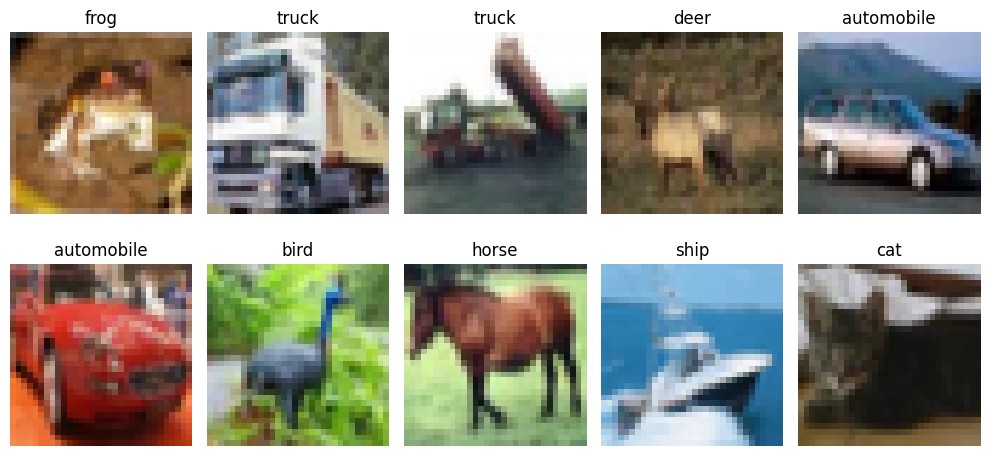

In [3]:
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.tight_layout()
plt.savefig("images/sample_images.png", dpi=150, bbox_inches='tight')
plt.show()

## Check class balance and normalize the images

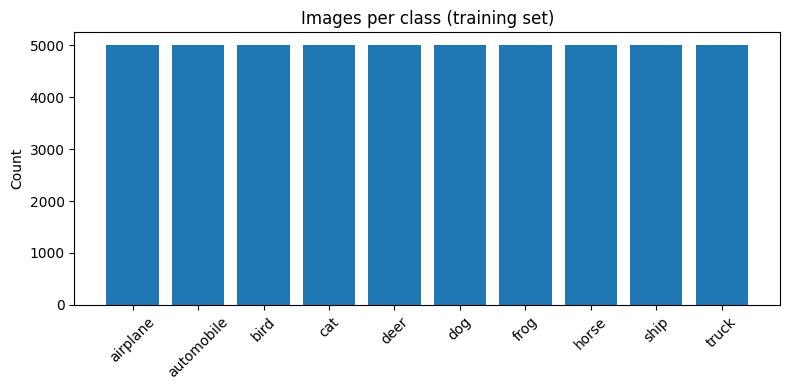

{'airplane': np.int64(5000), 'automobile': np.int64(5000), 'bird': np.int64(5000), 'cat': np.int64(5000), 'deer': np.int64(5000), 'dog': np.int64(5000), 'frog': np.int64(5000), 'horse': np.int64(5000), 'ship': np.int64(5000), 'truck': np.int64(5000)}


In [4]:
unique, counts = np.unique(y_train, return_counts=True)

plt.figure(figsize=(8, 4))
plt.bar(class_names, counts)
plt.xticks(rotation=45)
plt.title("Images per class (training set)")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("images/class_distribution.png", dpi=150, bbox_inches='tight')
plt.show()

print(dict(zip(class_names, counts)))

Pixel values are 0-255. Dividing by 255 puts them between 0 and 1,
which helps the network train faster and more stably.

In [5]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("New pixel range:", x_train.min(), "to", x_train.max())

New pixel range: 0.0 to 1.0


## Data Augmentation

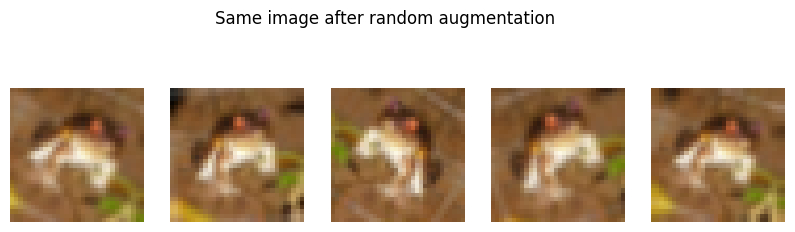

In [6]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="data_augmentation")

# preview the same image with 5 random augmentations
plt.figure(figsize=(10, 3))
for i in range(5):
    aug = data_augmentation(np.expand_dims(x_train[0], axis=0), training=True)
    plt.subplot(1, 5, i + 1)
    plt.imshow(aug[0])
    plt.axis('off')
plt.suptitle("Same image after random augmentation")
plt.savefig("images/augmentation_preview.png", dpi=150, bbox_inches='tight')
plt.show()

## CNN

In [7]:
cnn_model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

## Training the CNN model

In [8]:
cnn_model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = cnn_model.fit(x_train, y_train,
                        epochs=30,
                        batch_size=64,
                        validation_split=0.1,
                        callbacks=[early_stop])

Epoch 1/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.3394 - loss: 1.7999 - val_accuracy: 0.4704 - val_loss: 1.4489
Epoch 2/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4600 - loss: 1.4987 - val_accuracy: 0.5290 - val_loss: 1.2782
Epoch 3/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.5017 - loss: 1.3847 - val_accuracy: 0.5912 - val_loss: 1.1593
Epoch 4/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.5436 - loss: 1.2959 - val_accuracy: 0.5906 - val_loss: 1.1726
Epoch 5/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.5568 - loss: 1.2482 - val_accuracy: 0.6486 - val_loss: 0.9850
Epoch 6/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5819 - loss: 1.1953 - val_accuracy: 0.6480 - val_loss: 0.9914
Epoch 7/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.5926 - loss: 1.1668 - val_accuracy: 0.6612 - val_loss: 0.9572
Epoch 8/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6035 - loss: 1.1390 - val_accuracy:

## Training curves

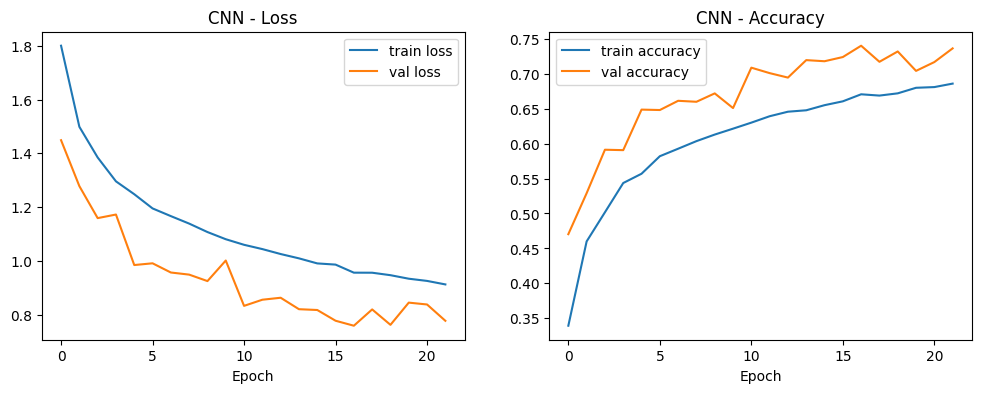

In [9]:
def plot_history(h, title, filename):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(h.history['loss'], label='train loss')
    plt.plot(h.history['val_loss'], label='val loss')
    plt.title(title + " - Loss")
    plt.xlabel("Epoch")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(h.history['accuracy'], label='train accuracy')
    plt.plot(h.history['val_accuracy'], label='val accuracy')
    plt.title(title + " - Accuracy")
    plt.xlabel("Epoch")
    plt.legend()

    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()

plot_history(history, "CNN", "images/cnn_training_curves.png")

## Test accuracy

In [10]:
cnn_loss, cnn_acc = cnn_model.evaluate(x_test, y_test)
print("CNN test accuracy:", round(cnn_acc, 4))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7285 - loss: 0.7838
CNN test accuracy: 0.7285


## Report and confusion matrix

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
              precision    recall  f1-score   support

    airplane       0.70      0.82      0.75      1000
  automobile       0.85      0.87      0.86      1000
        bird       0.72      0.52      0.61      1000
         cat       0.56      0.53      0.54      1000
        deer       0.73      0.64      0.68      1000
         dog       0.61      0.67      0.64      1000
        frog       0.79      0.78      0.78      1000
       horse       0.74      0.79      0.76      1000
        ship       0.79      0.88      0.83      1000
       truck       0.81      0.79      0.80      1000

    accuracy                           0.73     10000
   macro avg       0.73      0.73      0.73     10000
weighted avg       0.73      0.73      0.73     10000



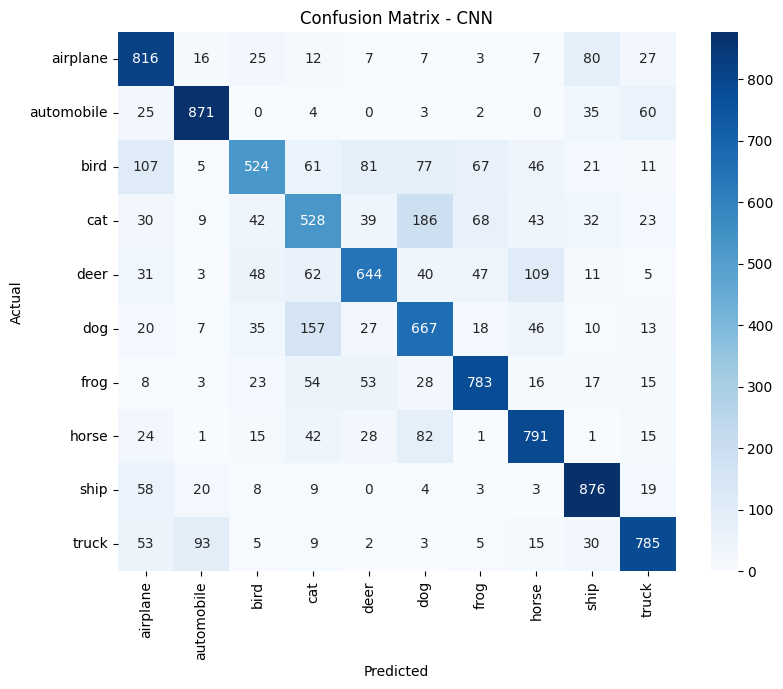

In [11]:
y_pred = np.argmax(cnn_model.predict(x_test), axis=1)

print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - CNN")
plt.savefig("images/cnn_confusion_matrix.png", dpi=150, bbox_inches='tight')
plt.show()

## some wrong predictions

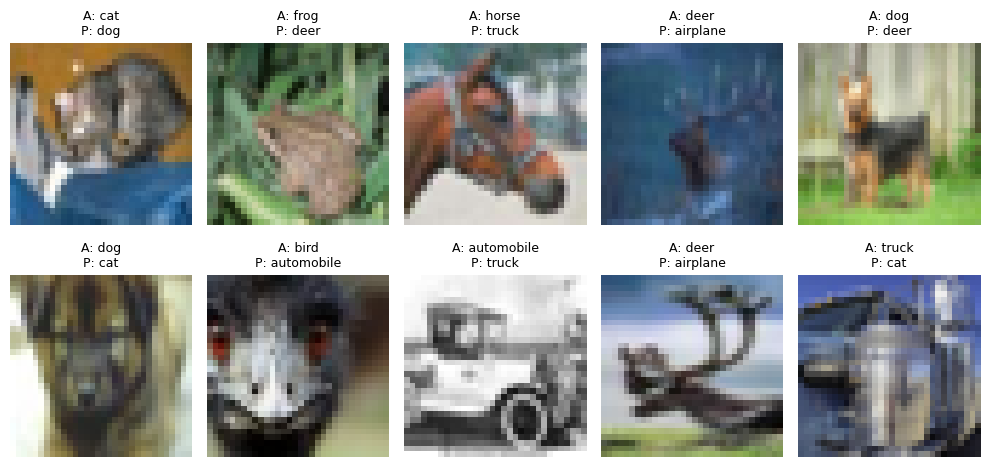

In [12]:
wrong = np.where(y_pred != y_test)[0]

plt.figure(figsize=(10, 5))
for i, idx in enumerate(wrong[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx])
    plt.title("A: " + class_names[y_test[idx]] + "\nP: " + class_names[y_pred[idx]], fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.savefig("images/wrong_predictions.png", dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
## Transfer learning with MobileNetV2

In [13]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(input_shape=(96, 96, 3),
                         include_top=False,
                         weights='imagenet')
base_model.trainable = False   # freeze the pretrained layers

inputs = tf.keras.Input(shape=(32, 32, 3))
x = data_augmentation(inputs)
x = layers.Resizing(96, 96)(x)
x = layers.Rescaling(2.0, offset=-1.0)(x)   # our data is 0 to 1, MobileNetV2 expects -1 to 1
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)

tl_model = tf.keras.Model(inputs, outputs)
tl_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Training the model

In [14]:
tl_model.compile(optimizer='adam',
                 loss='sparse_categorical_crossentropy',
                 metrics=['accuracy'])

early_stop2 = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history_tl = tl_model.fit(x_train, y_train,
                          epochs=10,
                          batch_size=64,
                          validation_split=0.1,
                          callbacks=[early_stop2])

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 28ms/step - accuracy: 0.5832 - loss: 1.2420 - val_accuracy: 0.7974 - val_loss: 0.5867
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6605 - loss: 0.9768 - val_accuracy: 0.8056 - val_loss: 0.5715
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6755 - loss: 0.9435 - val_accuracy: 0.8202 - val_loss: 0.5239
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 28ms/step - accuracy: 0.6798 - loss: 0.9310 - val_accuracy: 0.8126 - val_loss: 0.5381
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - accuracy: 0.6805 - loss: 0.9252 - val_accuracy: 0.8234 - val_loss: 0.5124
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - accuracy: 0.6825 - loss: 0.9239 - val_accuracy: 0.8170 - val_loss: 0.5310
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6797 - loss: 0.9263 - val_accuracy: 0.8202 - val_loss: 0.5152
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - accuracy: 0.6768 - loss: 0.9264 - 

## Curves and test accuracy

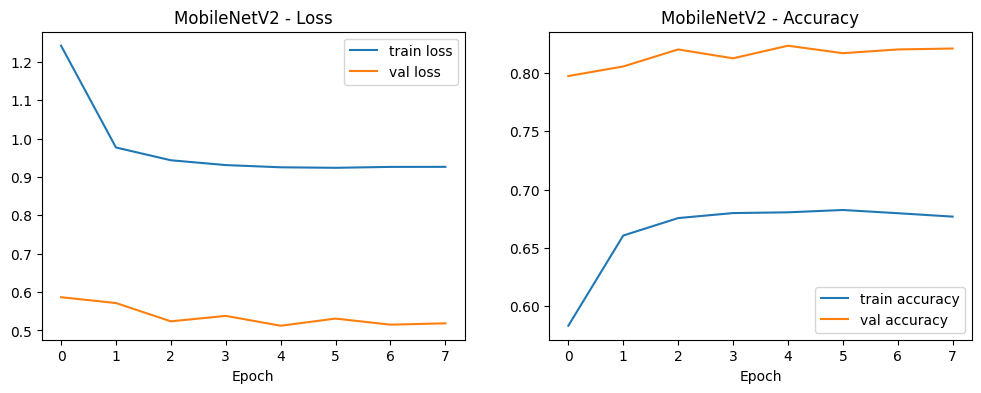

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8171 - loss: 0.5296
MobileNetV2 test accuracy: 0.8171


In [16]:
plot_history(history_tl, "MobileNetV2", "images/mobilenetv2_training_curves.png")

tl_loss, tl_acc = tl_model.evaluate(x_test, y_test)
print("MobileNetV2 test accuracy:", round(tl_acc, 4))

## Comparision chart

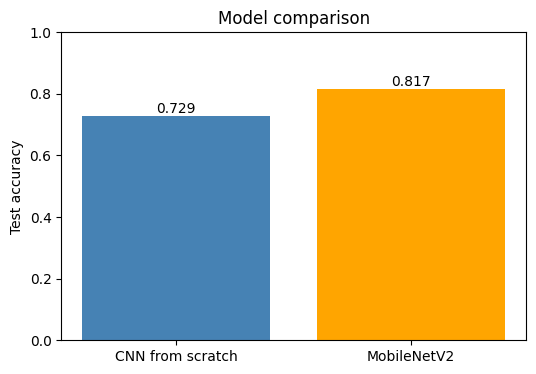

In [17]:
plt.figure(figsize=(6, 4))
plt.bar(['CNN from scratch', 'MobileNetV2'], [cnn_acc, tl_acc], color=['steelblue', 'orange'])
plt.ylabel("Test accuracy")
plt.ylim(0, 1)
plt.title("Model comparison")
for i, v in enumerate([cnn_acc, tl_acc]):
    plt.text(i, v + 0.01, str(round(v, 3)), ha='center')
plt.savefig("images/model_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

## saving the model

In [19]:
tl_model.save("models/cifar10_mobilenetv2.keras")

In [20]:
import shutil
from google.colab import files

shutil.make_archive("project_images", "zip", "images")
files.download("project_images.zip")
files.download("models/cifar10_mobilenetv2.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

####
- The CNN built from scratch reached 72.85% test accuracy, while MobileNetV2 with transfer learning reached 81.71%, which is about 9 points higher.
- Transfer learning helped because MobileNetV2 was already trained on ImageNet, so it had learned general features like edges, textures and shapes. It only had to learn the final classifier, while my CNN had to learn everything from 50,000 small images.
- The CNN did not overfit. Validation accuracy stayed above training accuracy because augmentation and dropout are only active during training, so the training images were harder than the clean validation images. EarlyStopping stopped training at epoch 22 and restored the best weights.
- The hardest classes were cat (F1 0.54), bird (0.61) and dog (0.64). The easiest were automobile (0.86), ship (0.83) and truck (0.80). In the confusion matrix, [ADD: the pair with the biggest off-diagonal number] were confused most often.
- If I continued, I would fine-tune the top layers of MobileNetV2 instead of keeping the whole base frozen, and I would try a deeper CNN with batch normalization.